In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from utils.linear_model import get_ODR, get_OLS

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = 10**np.random.normal(0, 0.3, N) - 1
y = k * x + b + np.random.normal(0, sig, N)

y_err = np.abs(y) / np.random.uniform(2, 4, size=N)
y_obs = y + np.random.normal(0, y_err, N)

x_err = np.abs(x) / np.random.uniform(3, 5, size=N)
x_obs = x + np.random.normal(0, x_err, N)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [ ]:
res_ODR = get_ODR(x_obs, y_obs)
res_wODR = get_ODR(x_obs, y_obs, x_err=x_err, y_err=y_err)
res_OLS = get_OLS(x_obs, y_obs)

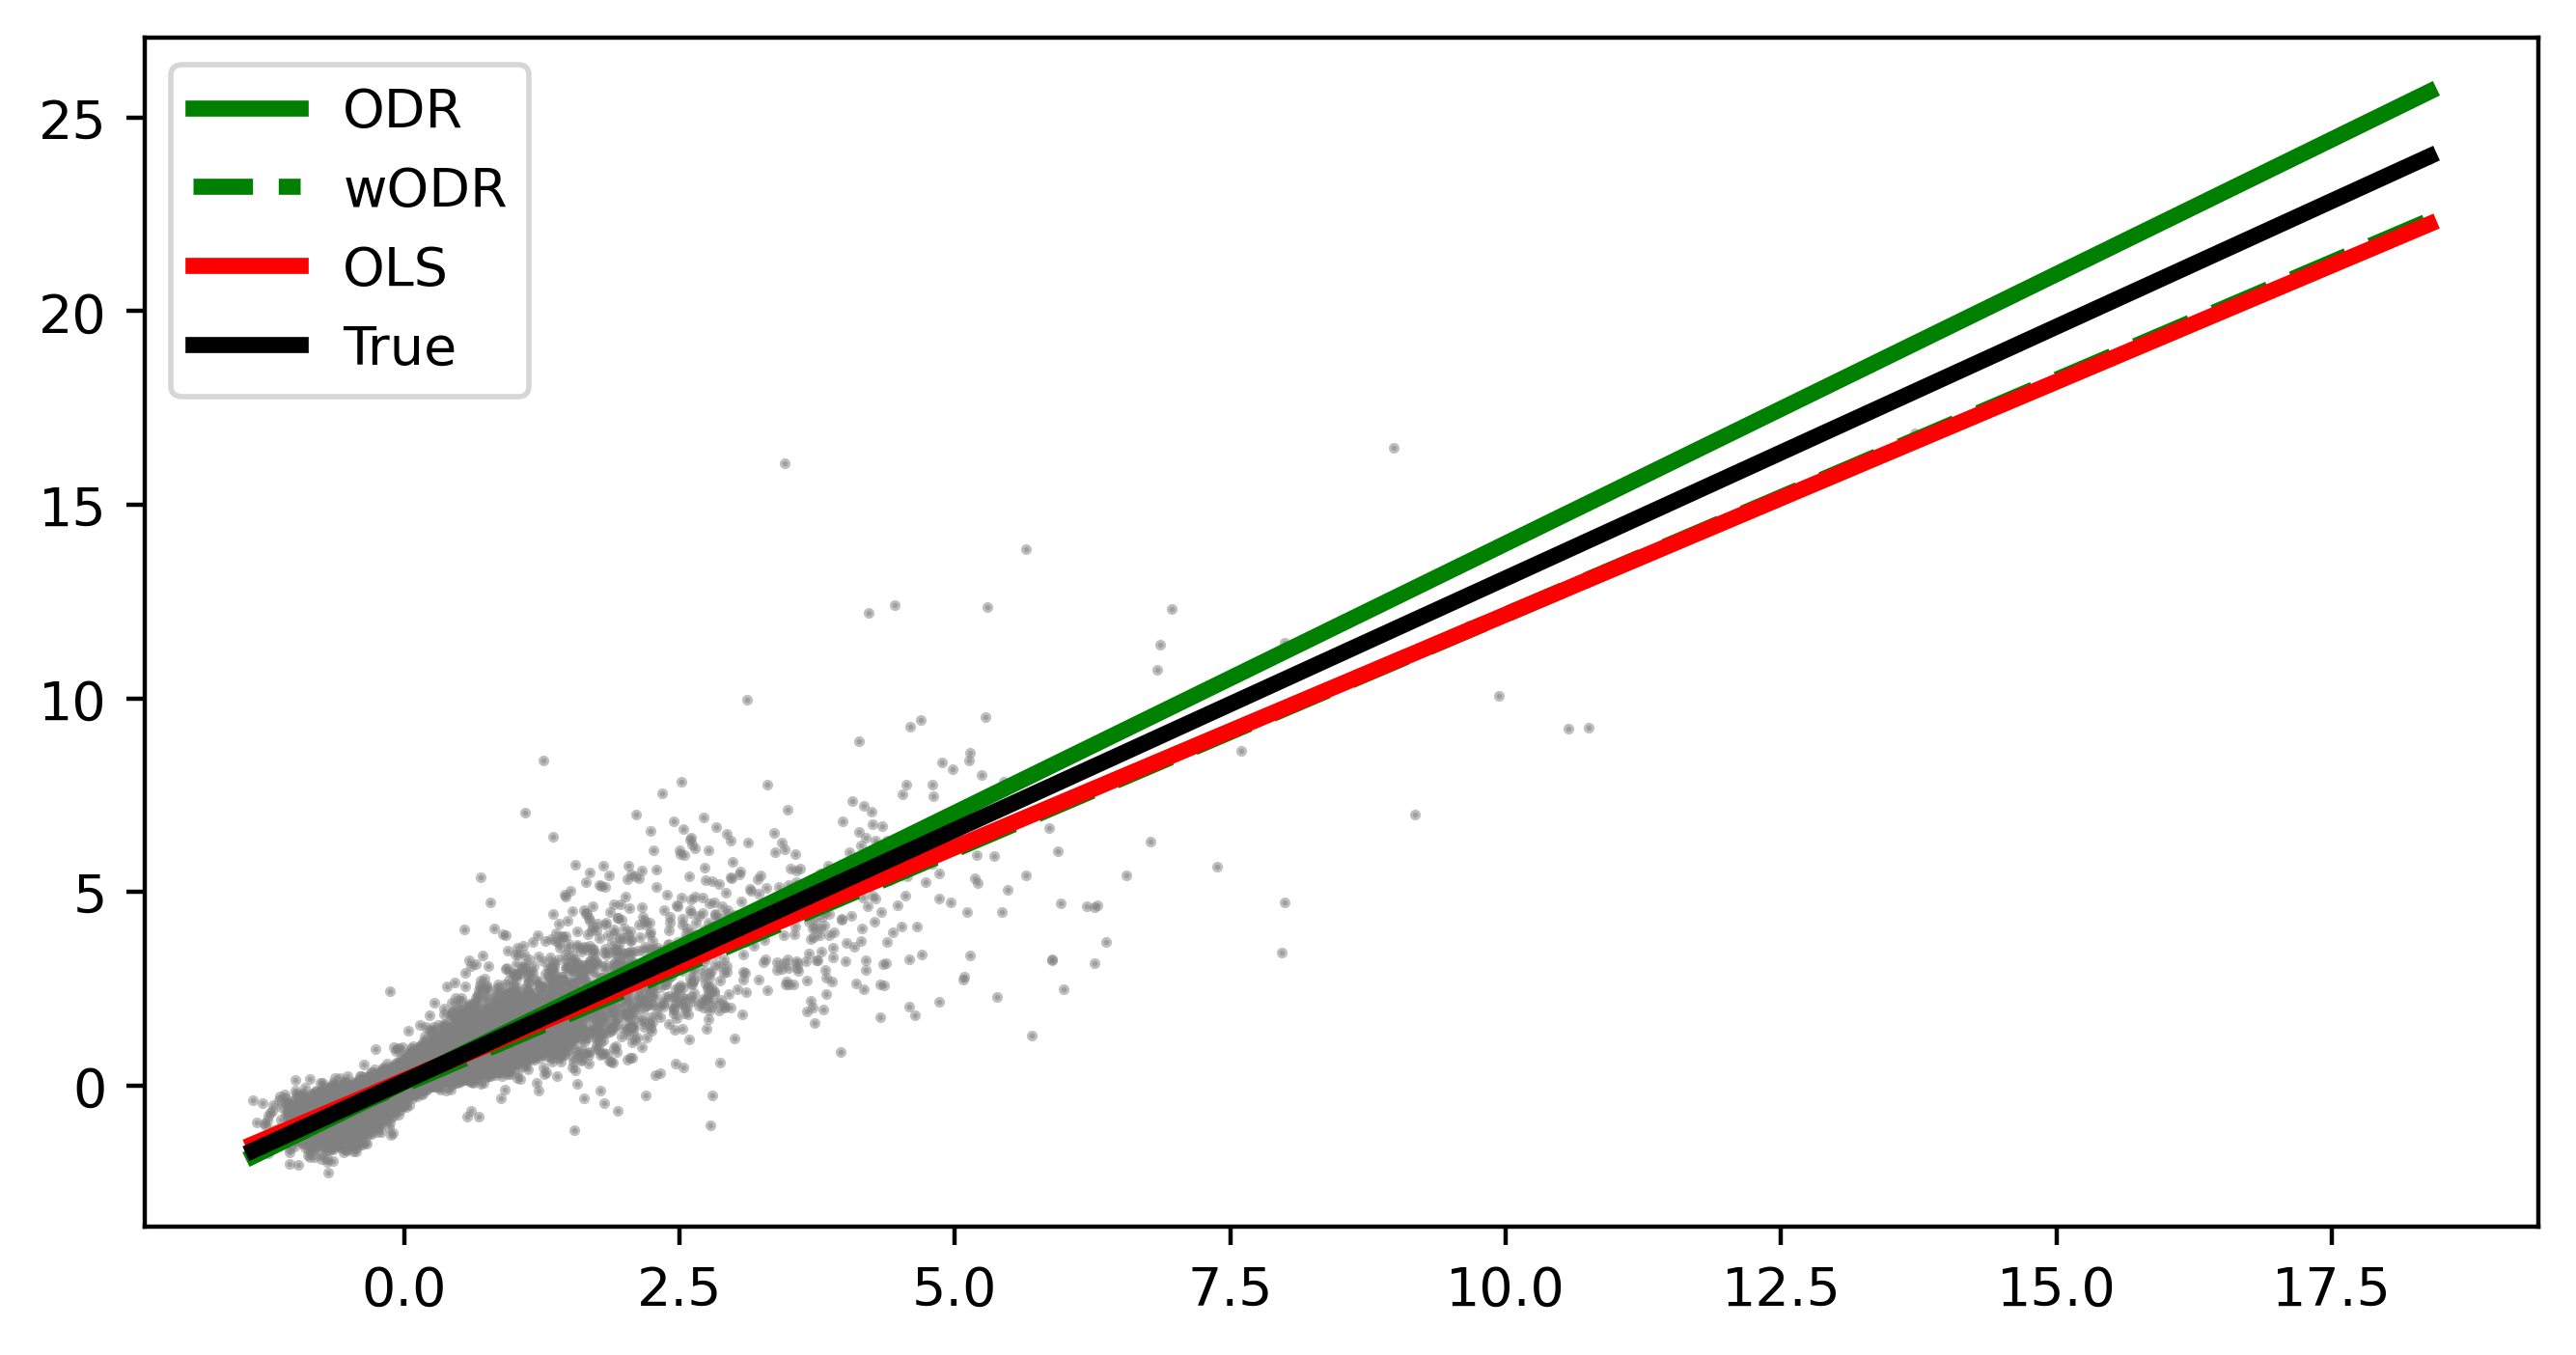

In [ ]:
plt.figure(figsize=(8, 4), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(x_obs.min(), x_obs.max(), 100)
yy = k * xx + b
yy_ODR = res_ODR['func_xy'](xx)
yy_wODR = res_wODR['func_xy'](xx)
yy_OLS = res_OLS['func'](xx)

plt.plot(xx, yy_ODR, color='green', label='ODR', linestyle='-', lw=3)
plt.plot(xx, yy_wODR, color='green', label='wODR', linestyle='--', lw=3)
plt.plot(xx, yy_OLS, color='red', label='OLS', linestyle='-', lw=3)
plt.plot(xx, yy, color='black', label='True', lw=3)

plt.legend()

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LinearML, LinearKS
import optax

In [ ]:
xflow = FlowVI(x_min=x_obs.min(),
               x_max=x_obs.max(),
               x_err_min=x_err.min() * 0.8,
               x_err_max=x_err.max() * 1.2,
               transfer=None)

xflow.fit(x_obs,
          x_err,
          verbose=True,
          n_pre=500,
          max_stuck=20,
          stuck_frac=0.02,
          optimizer=optax.adam(3e-4))

100%|██████████| 500/500 [00:24<00:00, 20.63it/s]


step 0: loss -0.7069362998008728
step 10: loss -0.8840972185134888
step 20: loss -0.9168895483016968
step 30: loss -0.9411966800689697
step 40: loss -0.9582761526107788
step 50: loss -0.9710720181465149
step 60: loss -0.9823299646377563
step 70: loss -0.9930986166000366
step 80: loss -0.9995957612991333
step 90: loss -1.0037275552749634
step 100: loss -0.9954790472984314
step 110: loss -1.0040028095245361
step 120: loss -1.0072587728500366
step 130: loss -1.0106152296066284
step 140: loss -1.0108835697174072
step 150: loss -1.0137375593185425
step 160: loss -1.0160866975784302
step 170: loss -1.017538070678711
step 180: loss -1.0186145305633545
step 190: loss -1.0195461511611938
step 200: loss -1.0203226804733276
step 210: loss -1.0209790468215942
step 220: loss -1.0216180086135864
step 230: loss -1.022165060043335
step 240: loss -1.0226274728775024


In [ ]:
xflow.ks_test(x_obs, x_err, 10000)

(0.015900015830993652, 0.29126154376026525)

In [ ]:
yflow = FlowVI(x_min=y_obs.min(),
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2)

yflow.fit(y_obs,
          y_err,
          verbose=True,
          n_pre=1000,
          max_stuck=10,
          stuck_frac=0.02)

100%|██████████| 1000/1000 [00:37<00:00, 26.55it/s]


step 0: loss 1.093483567237854
step 10: loss 0.3016112148761749
step 20: loss 0.22567111253738403
step 30: loss 0.1589156687259674
step 40: loss 0.14245519042015076
step 50: loss 0.12502004206180573
step 60: loss 0.12068283557891846
step 70: loss 0.11501740664243698
step 80: loss 0.11124801635742188
step 90: loss 0.10891121625900269
step 100: loss 0.13286329805850983
step 110: loss 0.10808078199625015
step 120: loss 0.10794457793235779
step 130: loss 0.10570130497217178
step 140: loss 0.11650566011667252
step 150: loss 0.1061927005648613
step 160: loss 0.11380008608102798
step 170: loss 0.10646434128284454
step 180: loss 0.10121215134859085
step 190: loss 0.10197276622056961
step 200: loss 0.10101068019866943
step 210: loss 0.10239706188440323
step 220: loss 0.11461811512708664
step 230: loss 0.107757568359375
step 240: loss 0.10766879469156265
step 250: loss 0.1057678684592247
step 260: loss 0.10114355385303497
step 270: loss 0.0999654084444046
step 280: loss 0.09905199706554413
step 

In [ ]:
yflow.ks_test(y_obs, y_err, 10000)

(0.018149985000491142, 0.17072057524942752)

### ML Based Method

In [ ]:
from scipy.stats import qmc
from corner import corner

In [ ]:
linear_ML = LinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1.0, 0., 0.1],
    int_method='ghq',
    ignore_y_err_c_y=True,
    n=51,
    flow_batch_size=500_000,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0001997 0.0027511988 0.10490827 1.5490439
1000 1.1903162 0.10181461 0.18790354 1.7927905
2000 1.208284 0.10314893 0.18914586 1.793279
3000 1.2096641 0.10324928 0.18925159 1.793282
converged, so stop with 3000 iterations


In [ ]:
params_ml, params_std, cov = linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1.0, 0., 0.1],
    int_method='qgrid',  # different integration method
    ignore_y_err_c_y=True,
    n=51,
    flow_batch_size=500_000,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0008101 0.0028929065 0.104385324 0.028462859
1000 1.0750743 0.08676242 0.17784458 0.22414286
2000 1.0751631 0.08675842 0.1778572 0.2241429
converged, so stop with 2000 iterations


In [ ]:
params_ml, params_std, cov = linear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err,
    [1.0, 0., 0.1],
    int_method='auto',
    ignore_y_err_c_y=True,
    n=51,
    flow_batch_size=500_000,
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)

0 1.0001997 0.0027511988 0.10490827 1.5490439
1000 1.1903162 0.10181461 0.18790354 1.7927905
2000 1.208284 0.10314893 0.18914586 1.793279
3000 1.2096641 0.10324928 0.18925159 1.793282
converged, so stop with 3000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.2096641 0.10324928 0.18925159
Truth: 1.3 0.1 0.2


In [ ]:
sampler = qmc.Sobol(d=3, scramble=True)
l_bounds = [
    max(params_ml[0] - 0.02, -2),
    max(params_ml[1] - 0.02, -2),
    max(params_ml[2] - 0.02, 0.1)
]
u_bounds = [
    min(params_ml[0] + 0.02, 2),
    min(params_ml[1] + 0.02, 2),
    min(params_ml[2] + 0.02, 0.5)
]
params_grid = qmc.scale(sampler.random_base2(m=15), l_bounds, u_bounds)

log_posterior = linear_ML.log_posterior(x_obs, x_err, y_obs,
                                                     y_err, params_grid)

weight = jnp.exp(log_posterior - log_posterior.max())

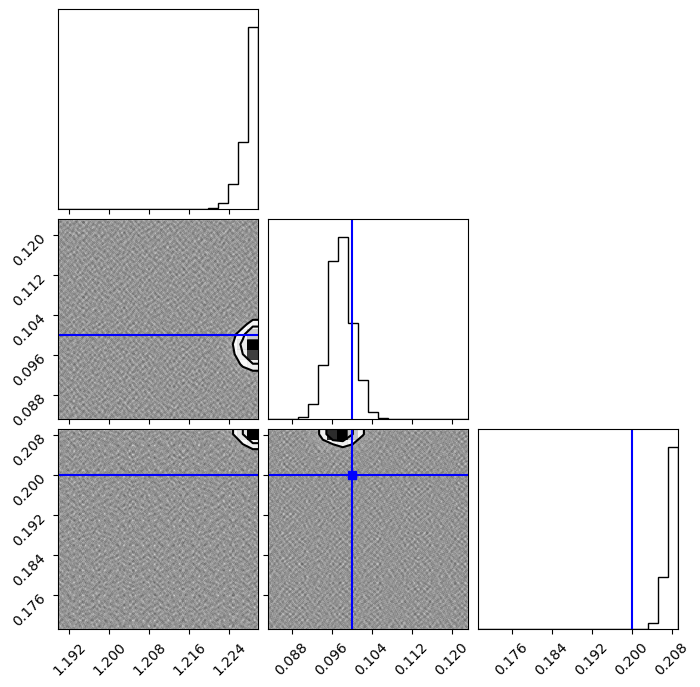

In [ ]:
cor_fig = corner(np.asarray(params_grid),
                 weights=weight,
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue')

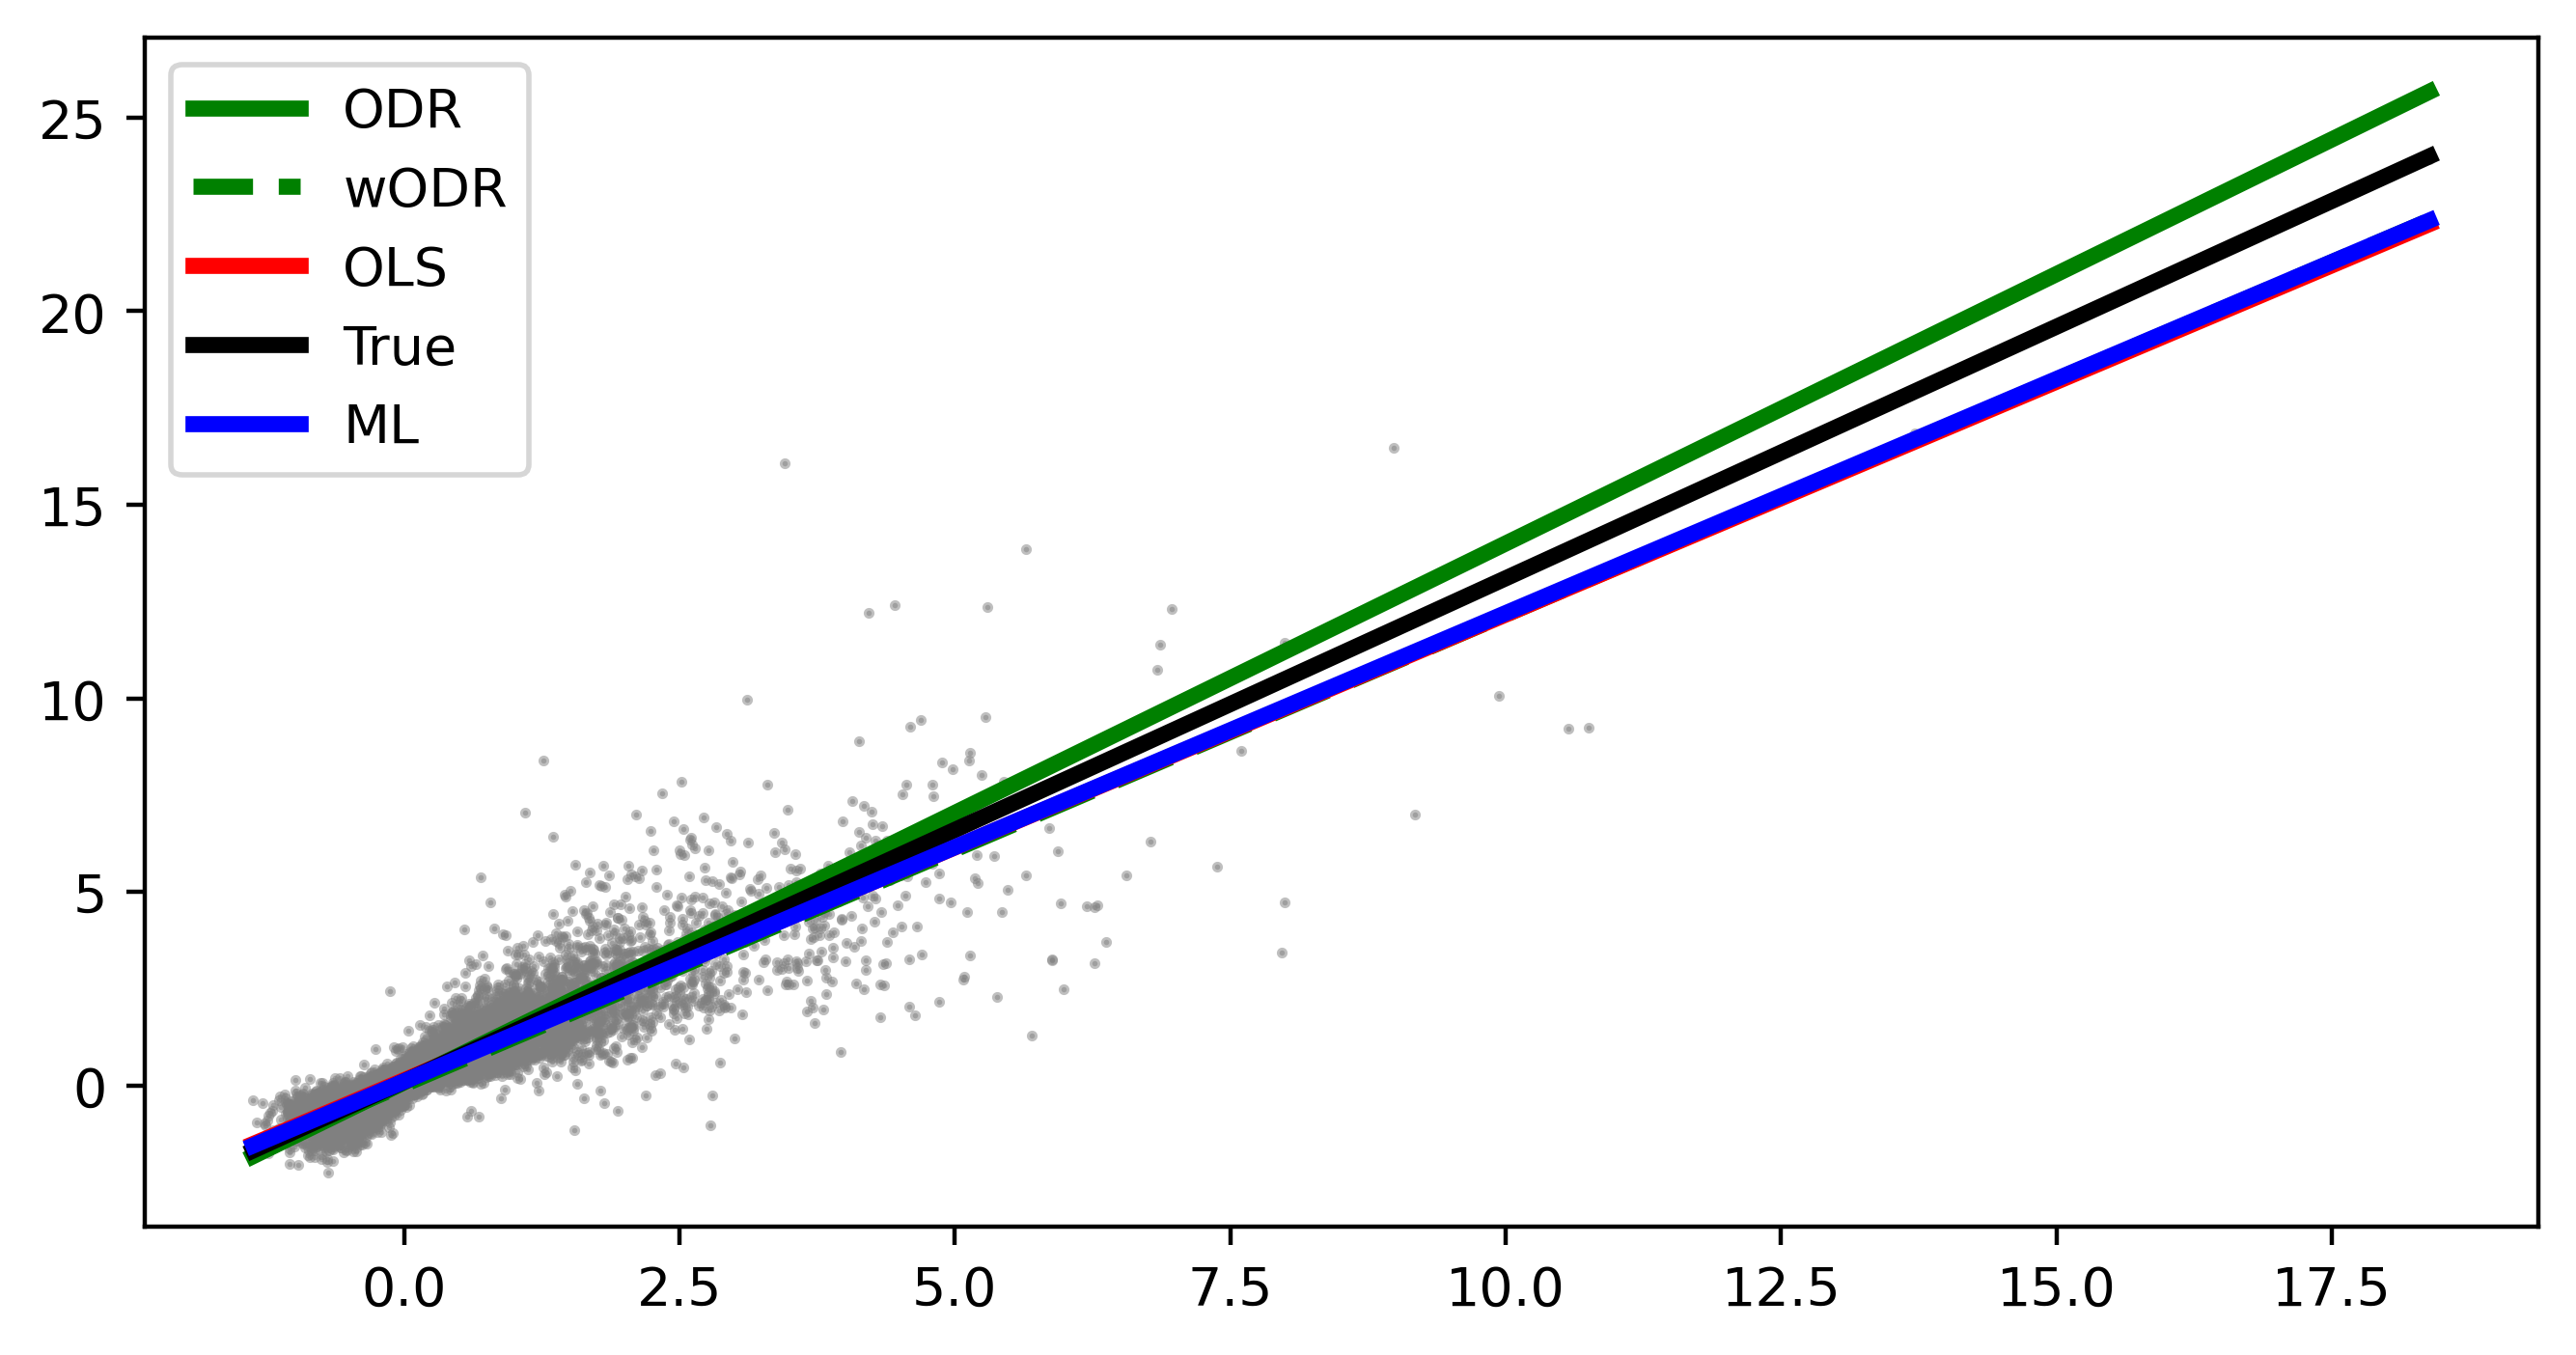

In [ ]:
plt.figure(figsize=(8, 4), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(x_obs.min(), x_obs.max(), 100)
yy = k * xx + b
yy_ML = params_ml[0] * xx + params_ml[1]

plt.plot(xx, yy_ODR, color='green', label='ODR', linestyle='-', lw=3)
plt.plot(xx, yy_wODR, color='green', label='wODR', linestyle='--', lw=3)
plt.plot(xx, yy_OLS, color='red', label='OLS', linestyle='-', lw=3)
plt.plot(xx, yy, color='black', label='True', lw=3)

plt.plot(xx, yy_ML, color='blue', label='ML', linestyle='-', lw=3)

plt.legend()

### KS Based Method

In [ ]:
linear_KS = LinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = linear_KS.fit(x_obs,
                                                 y_obs,
                                                 params_list=[
                                                     np.linspace(0.5, 1.5, 7),
                                                     np.linspace(-0.1, 0.3, 7),
                                                     np.linspace(0.1, 0.3, 5)
                                                 ],
                                                 verbose=True)
print(params_mean, params_std)

----
k: 1.301 +/- 0.100
b: 0.098 +/- 0.035
sig: 0.185 +/- 0.059
----
k: 1.285 +/- 0.096
b: 0.095 +/- 0.035
sig: 0.192 +/- 0.096
----
k: 1.286 +/- 0.094
b: 0.098 +/- 0.034
sig: 0.189 +/- 0.095
----
k: 1.294 +/- 0.100
b: 0.097 +/- 0.035
sig: 0.193 +/- 0.093
----
k: 1.289 +/- 0.094
b: 0.096 +/- 0.035
sig: 0.198 +/- 0.095
----
k: 1.290 +/- 0.096
b: 0.096 +/- 0.034
sig: 0.197 +/- 0.097
----
k: 1.281 +/- 0.103
b: 0.095 +/- 0.036
sig: 0.197 +/- 0.096
----
k: 1.286 +/- 0.096
b: 0.096 +/- 0.036
sig: 0.193 +/- 0.094
----
k: 1.285 +/- 0.098
b: 0.097 +/- 0.035
sig: 0.193 +/- 0.092
----
k: 1.289 +/- 0.095
b: 0.097 +/- 0.036
sig: 0.187 +/- 0.095
----
k: 1.288 +/- 0.096
b: 0.098 +/- 0.035
sig: 0.191 +/- 0.093
max iteration reached
[1.28555627 0.09541501 0.19349973] [0.09536409 0.03484653 0.0915061 ]


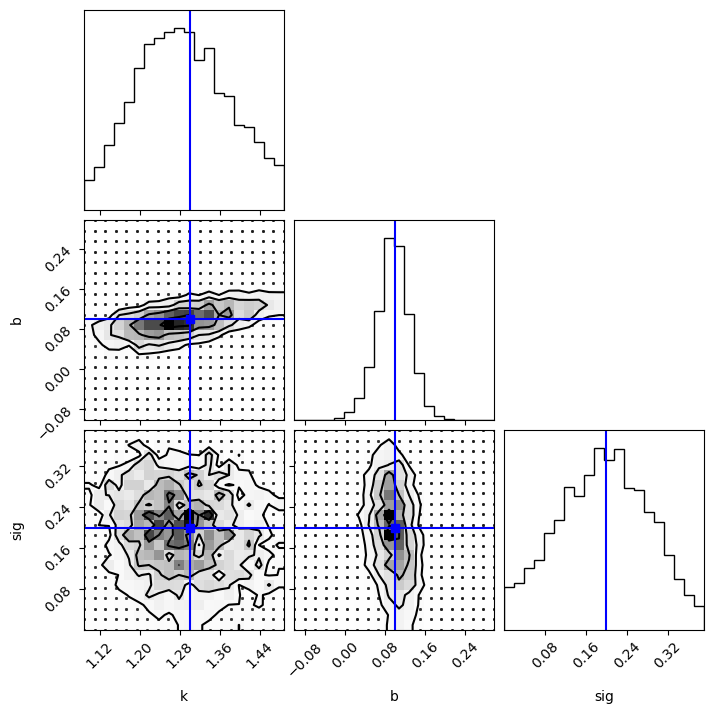

In [ ]:
cor_fig = corner(np.asarray(res_arr[:, :3]),
                 weights=res_arr[:, -1],
                 bins=20,
                 truths=[k, b, sig],
                 truth_color='blue',
                 labels=['k', 'b', 'sig'])